# 02 — Features EDA

Distributions of the NUMERIC features, their correlation with the target
and with next-week return, multicollinearity between features, and
decile analysis for momentum and volatility (do high-momentum stocks
actually outperform next week?).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import data as data_mod
from src import features as feat_mod
from src import models as models_mod
from src import simulate as sim_mod
from src.target import make_target, time_split

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (10, 5)

# Same parameters as the fuller main.py run (50 tickers, 5 years).
# Downloads are cached under data/ (7-day freshness), so re-running is fast.
tickers = data_mod.get_universe(n=50)
prices = data_mod.download_prices(tickers, years=5)
macro = data_mod.download_macro(years=5)
french = data_mod.download_french_weekly()
spy = data_mod.download_benchmark(years=5)

feat = feat_mod.build_features(prices, macro=macro, french=french)
panel = make_target(feat)
numeric, dummies = feat_mod.feature_columns(panel)
print(f"Panel: {len(panel):,} rows, {len(numeric)} numeric + "
      f"{len(dummies)} dummy features")

Universe: 503 tickers from Wikipedia S&P 500 list.
Prices: using cache /home/hatch/workspace/stock-markets-analytics-project/data/prices_weekly.parquet
Macro: using cache /home/hatch/workspace/stock-markets-analytics-project/data/macro_weekly.parquet
French factors: using cache /home/hatch/workspace/stock-markets-analytics-project/data/french_weekly.parquet
Benchmark: using cache /home/hatch/workspace/stock-markets-analytics-project/data/spy_weekly.parquet


Features: 10,550 rows after dropping 2,550 incomplete rows; 50 tickers, 211 weeks.
Target: 10,500 rows, positive rate 0.200 (expected ~0.20).
Panel: 10,500 rows, 20 numeric + 11 dummy features


## Feature distributions

In [2]:
print(panel[numeric].describe().T[['mean', 'std', 'min', '50%', 'max']].round(3))

                 mean     std     min     50%     max
ret_1w          0.003   0.046  -0.336   0.003   0.773
ret_4w          0.014   0.093  -0.426   0.011   1.062
ret_12w         0.042   0.170  -0.552   0.032   2.982
vol_4w          0.274   0.187   0.002   0.230   2.328
vol_12w         0.298   0.146   0.013   0.262   1.370
rsi_14         54.047  11.414  18.288  53.979  95.702
macd            2.389   9.593 -58.263   1.407  86.678
macd_signal     2.269   8.957 -50.020   1.319  74.918
macd_hist       0.120   3.068 -38.779   0.120  29.162
dist_52w_high  -0.127   0.127  -0.896  -0.090   0.000
dist_52w_low    0.371   0.507   0.000   0.265   9.535
vol_ratio_4w    0.004   0.269  -0.868  -0.026   2.077
vix            17.555   4.516  11.930  16.475  45.310
vix_chg_1w      0.015   0.170  -0.317  -0.009   1.093
tnx             4.226   0.386   3.288   4.243   5.277
tnx_chg_1w      0.005   0.128  -0.408   0.005   0.508
mkt_rf          0.003   0.020  -0.093   0.005   0.059
smb            -0.001   0.01

## Correlation with the target and with next-week return

Point-biserial correlation with the binary target (= Pearson on a 0/1
variable) and Pearson correlation with realised next-week return. Weekly
stock returns are noisy, so expect small numbers -- anything above ~0.05
in absolute value is already interesting.

               corr_target  corr_next_ret
vol_12w              0.147          0.054
vol_4w               0.108          0.044
dist_52w_high       -0.095         -0.039
dist_52w_low         0.090          0.028
rsi_14              -0.034         -0.031
ret_12w              0.013          0.001
macd_signal          0.011         -0.024
ret_1w              -0.010         -0.040
macd_hist           -0.009         -0.019
vol_ratio_4w         0.008         -0.000
macd                 0.008         -0.028
ret_4w              -0.000         -0.014
tnx                  0.000         -0.009
vix                  0.000          0.067
vix_chg_1w          -0.000          0.056
rf                   0.000          0.011
tnx_chg_1w           0.000         -0.069
hml                  0.000          0.006
mkt_rf              -0.000         -0.040
smb                  0.000         -0.018


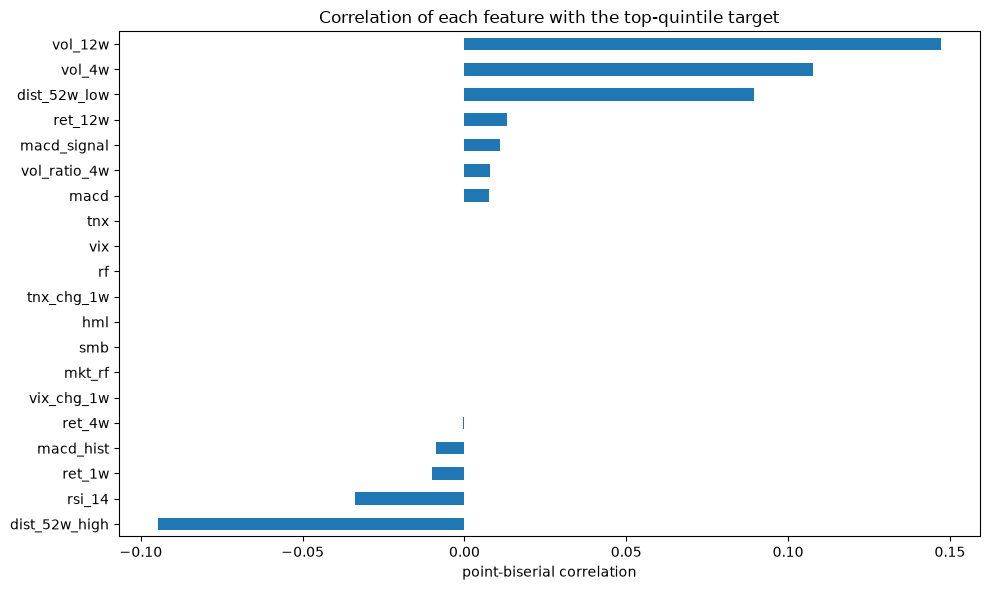

In [3]:
corr_t = panel[numeric + ['target']].corr()['target'].drop('target')
corr_r = panel[numeric + ['next_ret']].corr()['next_ret'].drop('next_ret')
ct = pd.DataFrame({'corr_target': corr_t, 'corr_next_ret': corr_r})
ct = ct.reindex(ct['corr_target'].abs().sort_values(ascending=False).index)
print(ct.round(3))
fig, ax = plt.subplots(figsize=(10, 6))
ct['corr_target'].sort_values().plot.barh(ax=ax)
ax.set_title('Correlation of each feature with the top-quintile target')
ax.set_xlabel('point-biserial correlation')
plt.tight_layout()
plt.show()

## Multicollinearity between features

Highly correlated features (e.g. ret_4w vs ret_12w, vol_4w vs vol_12w)
are expected -- they are nested windows of the same series. The Ridge
factor regression handles this with regularisation; tree models are
largely unaffected.

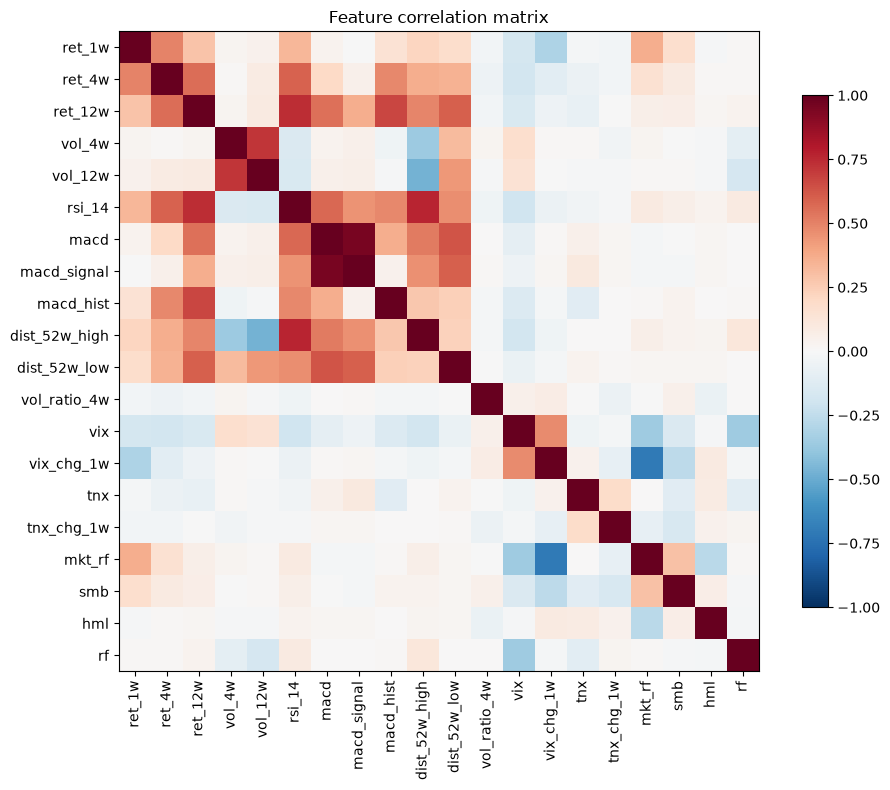

macd        macd_signal      0.948
rsi_14      dist_52w_high    0.764
ret_12w     rsi_14           0.738
vol_4w      vol_12w          0.714
vix_chg_1w  mkt_rf           0.708
ret_12w     macd_hist        0.672
macd        dist_52w_low     0.633
ret_12w     dist_52w_low     0.600
dtype: float64


In [4]:
c = panel[numeric].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(c.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric)))
ax.set_xticklabels(numeric, rotation=90)
ax.set_yticks(range(len(numeric)))
ax.set_yticklabels(numeric)
ax.set_title('Feature correlation matrix')
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()
# Strongest off-diagonal pairs.
pairs = c.where(np.triu(np.ones_like(c, dtype=bool), k=1)).stack()
print(pairs.abs().sort_values(ascending=False).head(8).round(3))

## Decile analysis: momentum and volatility

Split all rows into deciles by a feature and look at the mean next-week
return (and top-quintile hit rate) per decile. A monotone pattern means
the feature carries signal; a flat pattern means it does not.


=== ret_12w deciles ===
        mean_next_ret  hit_rate     n
decile                               
1              0.0090    0.2800  1050
2              0.0047    0.2219  1050
3              0.0010    0.1495  1050
4              0.0013    0.1648  1050
5              0.0023    0.1867  1050
6              0.0001    0.1524  1050
7              0.0034    0.1924  1050
8              0.0045    0.2143  1050
9              0.0023    0.1857  1050
10             0.0043    0.2524  1050


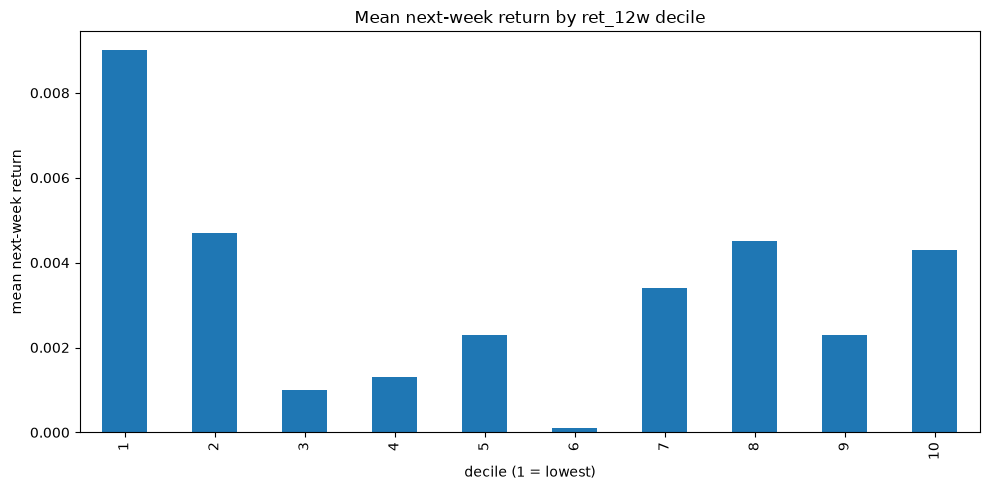


=== vol_12w deciles ===
        mean_next_ret  hit_rate     n
decile                               
1              0.0016    0.1352  1050
2              0.0037    0.1714  1050
3             -0.0006    0.1381  1050
4              0.0010    0.1552  1050
5              0.0033    0.1762  1050
6              0.0012    0.1857  1050
7              0.0050    0.2124  1050
8              0.0014    0.2162  1050
9              0.0057    0.2686  1050
10             0.0106    0.3410  1050


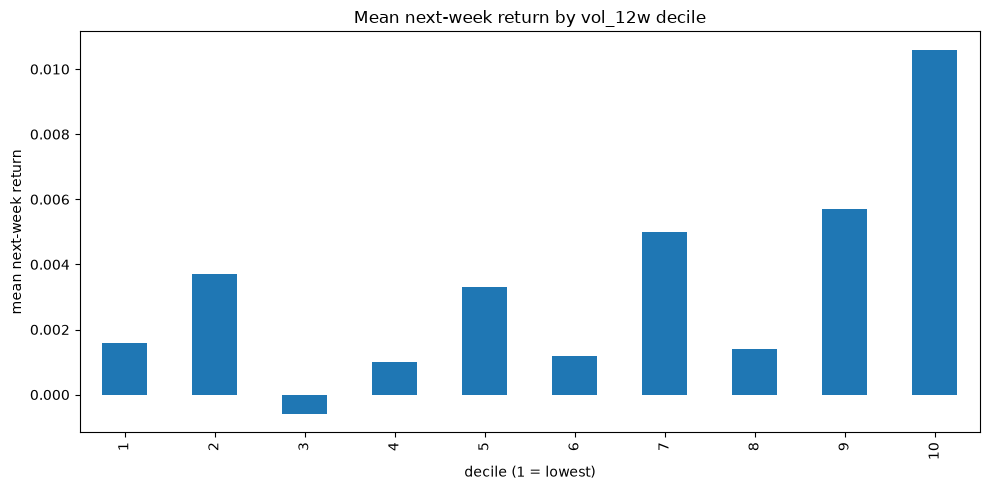


=== rsi_14 deciles ===
        mean_next_ret  hit_rate     n
decile                               
1              0.0076    0.2429  1050
2              0.0004    0.1800  1050
3              0.0063    0.2143  1050
4              0.0039    0.1981  1050
5              0.0023    0.2010  1050
6              0.0037    0.2019  1050
7              0.0046    0.2038  1050
8              0.0007    0.1914  1050
9              0.0019    0.1924  1050
10             0.0015    0.1743  1050


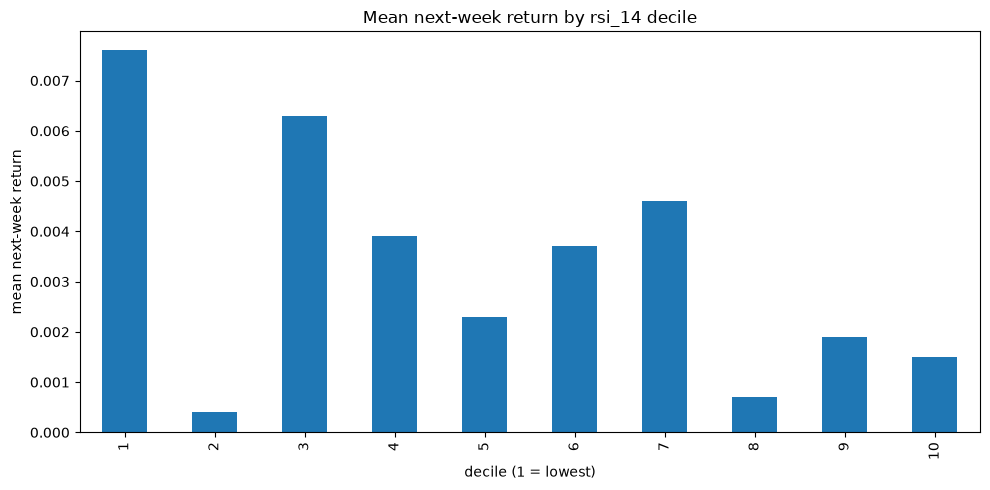

In [5]:
def decile_table(col: str) -> pd.DataFrame:
    d = panel[['date', 'ticker', col, 'next_ret', 'target']].copy()
    d['decile'] = pd.qcut(d[col], 10, labels=False, duplicates='drop') + 1
    return d.groupby('decile').agg(
        mean_next_ret=('next_ret', 'mean'),
        hit_rate=('target', 'mean'),
        n=('next_ret', 'size')).round(4)

for col in ['ret_12w', 'vol_12w', 'rsi_14']:
    t = decile_table(col)
    print(f"\n=== {col} deciles ===")
    print(t)
    fig, ax = plt.subplots()
    t['mean_next_ret'].plot.bar(ax=ax)
    ax.set_title(f'Mean next-week return by {col} decile')
    ax.set_xlabel('decile (1 = lowest)')
    ax.set_ylabel('mean next-week return')
    plt.tight_layout()
    plt.show()